# Phase 3 — Healthy Baseline Model Evaluation

## Objective

The objective of this experiment is to establish a reproducible healthy baseline for the Self-Healing Machine Learning (SHML) system using logistic regression on the UCI Default of Credit Card Clients dataset.

This baseline will serve as the reference for evaluating model behavior under controlled data failures and measuring recovery effectiveness.

## Experimental Setup

- **Task:** Binary classification
- **Dataset:** UCI Default of Credit Card Clients
- **Observations:** 30,000
- **Predictor features:** 23
- **Target:** `default payment next month`
- **Positive class:** 1 (default)
- **Baseline algorithm:** Logistic Regression
- **Training split:** 70%
- **Validation split:** 15%
- **Test split:** 15%
- **Random seed:** 42
- **Primary evaluation metric:** F1-score
- **Additional metrics:** Precision, Recall, ROC-AUC, Accuracy, and Confusion Matrix

## Baseline Evaluation Principles

1. Model fitting and preprocessing must use training data only.
2. Validation data will be used for baseline evaluation and subsequent controlled failure experiments.
3. Test data will remain untouched until final evaluation.
4. The baseline model configuration and evaluation results must be reproducible.
5. Positive-class recall will be examined because failing to identify actual defaults is an important prediction risk.

## Preliminary Healthy Baseline Results — Phase 1

The preliminary logistic regression experiment produced the following validation-set results:

| Metric | Value |
|---|---:|
| Accuracy | 0.8087 |
| Recall | 0.2402 |
| F1-score | 0.3570 |
| ROC-AUC | 0.7130 |

These values will be reproduced and extended in Phase 3.

The Phase 3 evaluation will additionally calculate precision, generate a confusion matrix, and compare the model with a simple majority-class benchmark.

Any differences from the preliminary results will be investigated to ensure that the dataset split, preprocessing, model configuration, and random seed remain consistent.

## Step 2 — Dataset Loading and Reproducible Data Splitting

The UCI Default of Credit Card Clients dataset contains 30,000 observations and 23 predictor features.

The dataset is divided into three subsets:

- Training: 70% (21,000 observations)
- Validation: 15% (4,500 observations)
- Testing: 15% (4,500 observations)

Stratified sampling is used to preserve the approximate proportion of default and non-default observations across the three subsets.

A fixed random seed of 42 ensures that the partitioning procedure is reproducible.

The training subset will be used for model fitting and preprocessing. The validation subset will be used for model evaluation and controlled failure experiments. The test subset will remain untouched until the final evaluation.

In [1]:

import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split


In [2]:
from pathlib import Path

data_dir = Path("data/working")
candidates = sorted(data_dir.glob("*credit*card*clients*.xls*"))
if not candidates:
    raise FileNotFoundError(f"No dataset file found under {data_dir}")

DATA_PATH = str(candidates[0])
df = pd.read_excel(DATA_PATH, header=1)
df.head()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [3]:

target_column = "default payment next month"

X = df.drop(columns=["ID", target_column])
y = df[target_column]

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True))


Predictor shape: (30000, 23)
Target shape: (30000,)

Target distribution:
default payment next month
0    0.7788
1    0.2212
Name: proportion, dtype: float64


In [4]:
# Stage 1: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size = 0.30,
    random_state = 42,
    stratify=y
)

In [6]:
# Stage 2: divide temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [7]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (21000, 23)
Validation: (4500, 23)
Testing: (4500, 23)


In [8]:
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
        print(f"\n{name} class distribution:")
        print(labels.value_counts(normalize=True).sort_index())
    


Training class distribution:
default payment next month
0    0.77881
1    0.22119
Name: proportion, dtype: float64

Validation class distribution:
default payment next month
0    0.778889
1    0.221111
Name: proportion, dtype: float64

Testing class distribution:
default payment next month
0    0.778667
1    0.221333
Name: proportion, dtype: float64


In [9]:

assert len(X_train) + len(X_val) + len(X_test) == len(X)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)

print("Data split verification passed.")


Data split verification passed.


## Step 3 — Healthy Logistic Regression Baseline

The healthy baseline model is logistic regression, trained using the original, uncorrupted training dataset.

StandardScaler is used to standardize predictor features. The scaler is fitted exclusively on training data to prevent data leakage.

The trained scaler is then applied to the validation dataset without refitting.

Logistic regression is selected because it provides an interpretable, computationally efficient reference model for evaluating the SHML system.

The model uses `max_iter=1000` and `random_state=42`, consistent with Phase 1.

The validation set is used to reproduce baseline performance. The held-out test set remains untouched.

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Fit the scaler using training data only 
scaler = StandardScaler()

X_trained_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

#Train the healthy baseline model
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_model.fit(X_trained_scaled, y_train)
print("Healthy logistic regression baseline trained.")
print("Training observations:", X_train.shape[0])
print("Validation observations:", X_val.shape[0])


Healthy logistic regression baseline trained.
Training observations: 21000
Validation observations: 4500


In [11]:
#Predict classes 
y_val_pred = baseline_model.predict(X_val_scaled)

# predicted probabilities for class 1
y_val_prob = baseline_model.predict_proba(
    X_val_scaled
)[:, 1]

print("Validation predictions generated.")

Validation predictions generated.


In [12]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

baseline_metrics = {
    "Accuracy": accuracy_score(y_val, y_val_pred),
    "Precision": precision_score(y_val, y_val_pred),
    "Recall": recall_score(y_val, y_val_pred),
    "F1-score": f1_score(y_val, y_val_pred),
    "ROC-AUC": roc_auc_score(y_val, y_val_prob)
}

for metric, value in baseline_metrics.items():
    print(f"{metric}: {value:.4f}")


Accuracy: 0.8087
Precision: 0.6948
Recall: 0.2402
F1-score: 0.3570
ROC-AUC: 0.7130


## Step 4 — Confusion Matrix Analysis

The confusion matrix evaluates how the healthy logistic regression model classifies default and non-default observations.

It provides four outcomes:

- True Negative (TN): Correctly predicted non-default.
- False Positive (FP): Incorrectly predicted default.
- False Negative (FN): Incorrectly predicted non-default for a customer who actually defaults.
- True Positive (TP): Correctly predicted default.

False negatives are particularly important because they represent defaulting customers that the model fails to identify.

This analysis helps establish the baseline error patterns that the SHML system should monitor during recovery validation.

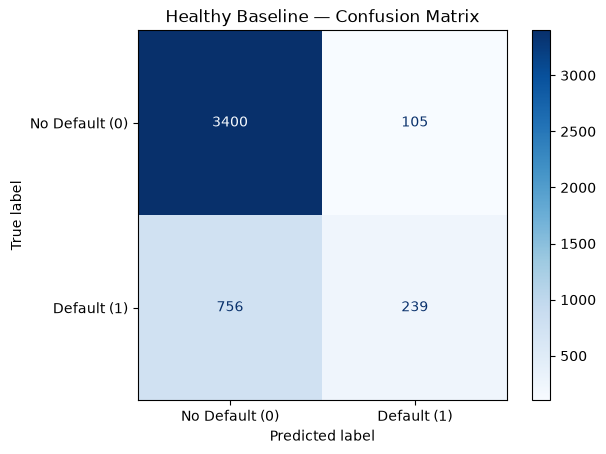

True Negatives: 3400
False Positives: 105
False Negatives: 756
True Positives: 239


In [13]:
from sklearn.metrics  import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
cm = confusion_matrix(y_val, y_val_pred)

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default (0)", "Default (1)"]
)

display_cm.plot(cmap = "Blues", values_format="d")
plt.title("Healthy Baseline — Confusion Matrix")
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)



### Confusion Matrix — Findings

The healthy logistic regression model was evaluated using 4,500 validation observations.

The confusion matrix produced the following results:

- True Negatives: 3,400
- False Positives: 105
- False Negatives: 756
- True Positives: 239

The model correctly identified 239 of the 995 actual default cases, resulting in a positive-class recall of approximately 24.02%.

Although the model achieved 80.87% accuracy, it failed to identify approximately 75.98% of actual defaults.

This indicates that overall accuracy alone is insufficient for evaluating model reliability in this credit-default classification task.

For the SHML system, F1-score will remain the primary recovery evaluation metric, while positive-class recall should also be monitored to prevent accepting corrections that substantially reduce default detection.

These findings establish the healthy model's error profile for comparison with corrupted and recovered data batches.

In [16]:
import numpy as np 
# Majority class benchmark: always predict no default
y_majority_pred = np.zeros(len(y_val), dtype=int)

majority_metrics = {
    "Accuracy": accuracy_score(y_val, y_majority_pred),
    "Precision": precision_score(
        y_val, y_majority_pred, zero_division=0
    ),
    "Recall": recall_score(y_val, y_majority_pred),
    "F1-score": f1_score(y_val, y_majority_pred)
}

print("Majority-Class Benchmark")
for metric, value in majority_metrics.items():
    print(f"{metric}: {value:.4f}")
  

Majority-Class Benchmark
Accuracy: 0.7789
Precision: 0.0000
Recall: 0.0000
F1-score: 0.0000
